In [1]:
# Required imports

import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator 
from qiskit.circuit.library import VBERippleCarryAdder

# The VBE Modular Exponentiator

## Overview

The VBE Modular Exponentiator is a quantum circuit that finds the value of $a^x$ mod $N$. This notebook will build this circuit up starting from basic quantum gates. Each code block will introduce the user to the next layer up in the stack. The component circuits may therefore be run inidividually to see how they function; see below for a list of sections. As each layer builds upon the previous one, the user is advised to run the whole notebook before experimenting.  

### Sections

- **SUME and CARRY Gates**
- **The VBE Ripple Carry Adder (from Gates)**
- **The VBE Ripple Carry Adder (from Qiskit's Circuit Library)**
- **The VBE Modular Adder**
- **The VBE Modular Multiplier**
- **The VBE Modular Exponentiator**




### SUM and CARRY Gates

The SUM gate cosists of two CNOT gates. If $\ket{a}\ket{b}\ket{c}$ is the initial state, this gate finds $\ket{a}\ket{b}\ket{a+b+c}$. The CARRY gate consists of two Toffoli gates with a CNOT gate in between. If $\ket{a}\ket{b}\ket{c}$ is the initial state, this gate finds $\ket{a}\ket{b}\ket{ab+ac+bc}$. We will see in the next section how these gates work together to perform addition. Both gates implemented below.

The SUM Gate:


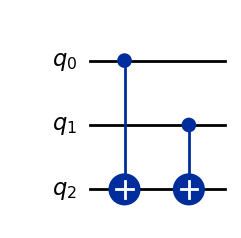

The CARRY Gate:


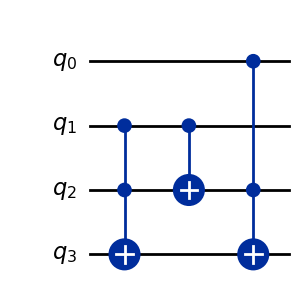

The inverse CARRY Gate:


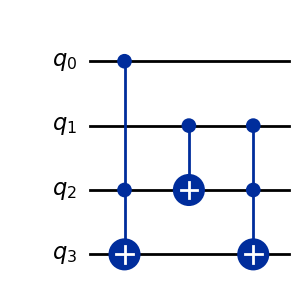

In [2]:

def SUM_GATE(show = False):
    """Creates a SUM gate"""

    # Create the circuit
    qc = QuantumCircuit(3, name="SUM")
    qc.cx(0, 2)
    qc.cx(1, 2)

    # Send created circuit to instruction
    sum_gate = qc.to_instruction()
    
    if (show == True):
        display(qc.draw("mpl"))

    return sum_gate

def CARRY_GATE(show = False):
    """Creates a CARRY gate"""

    # Create the circuit
    qc = QuantumCircuit(4, name="CARRY")
    qc.ccx(1, 2, 3)
    qc.cx(1, 2)
    qc.ccx(0, 2, 3) 

    # Send created circuit to instruction
    carry_gate = qc.to_instruction()

    if (show == True):
        display(qc.draw("mpl"))

    return carry_gate

def CARRY_INVERSE(show = False):
    """Creates an inverse CARRY gate"""

    # Create the circuit
    qc = QuantumCircuit(4, name="CARRY_INV")
    qc.ccx(0, 2, 3)
    qc.cx(1, 2)
    qc.ccx(1, 2, 3) 


    # Send the circuit to instruction
    carry_inv_gate = qc.to_instruction()

    if (show == True):
        display(qc.draw("mpl"))

    return carry_inv_gate

print("The SUM Gate:")
sum_gate = SUM_GATE(True)

print("The CARRY Gate:")
carry_gate = CARRY_GATE(True)

print("The inverse CARRY Gate:")
carry_inv_gate = CARRY_INVERSE(True)


### The VBE Ripple Carry Adder (from Gates)

The goal of this circuit is to find the sum of two integers a and b. The process is as follows: 

1. Each integer is written in its binary form as a = $a_{n-1}a_{n-2}...a_{1}a_{0}$, where $a_{i}$ corresponds to $a_{i} \cdot 2^{i}$ in decimal notation (so that $a = \sum_{i=0}^{n-1} a_{i} 2^{i}$).

2. A sequence of CARRY gates calculates the carry for each digit of the binary representation. For example, if $a_{0} = 1$ and $b_{0} = 1$, then $a_{0} + b_{0} = 0$ with 1 as the carry. This is checked for each digit in turn. 

3. If the last digit requires a carry, a CNOT gate stores this on the acilla qubit to prevent overflow.

4. The CARRY gates are undone by the inverse CARRY gate, while simultaneously a SUM gate calculates the sum. Combined this effect gives us $(carry bit) + ... + (a_2 + b_2) + (a_1 + b_1) + (a_0 + b_0)$ which results in the binary for a + b.

5. We measure the ancilla and the b register (now containing a + b bitwise) and convert the result back from binary to decimal.

Thus applying the VBE Ripple Carry Adder gate to $\ket{a}\ket{b}$ yields $\ket{a}\ket{a+b}$


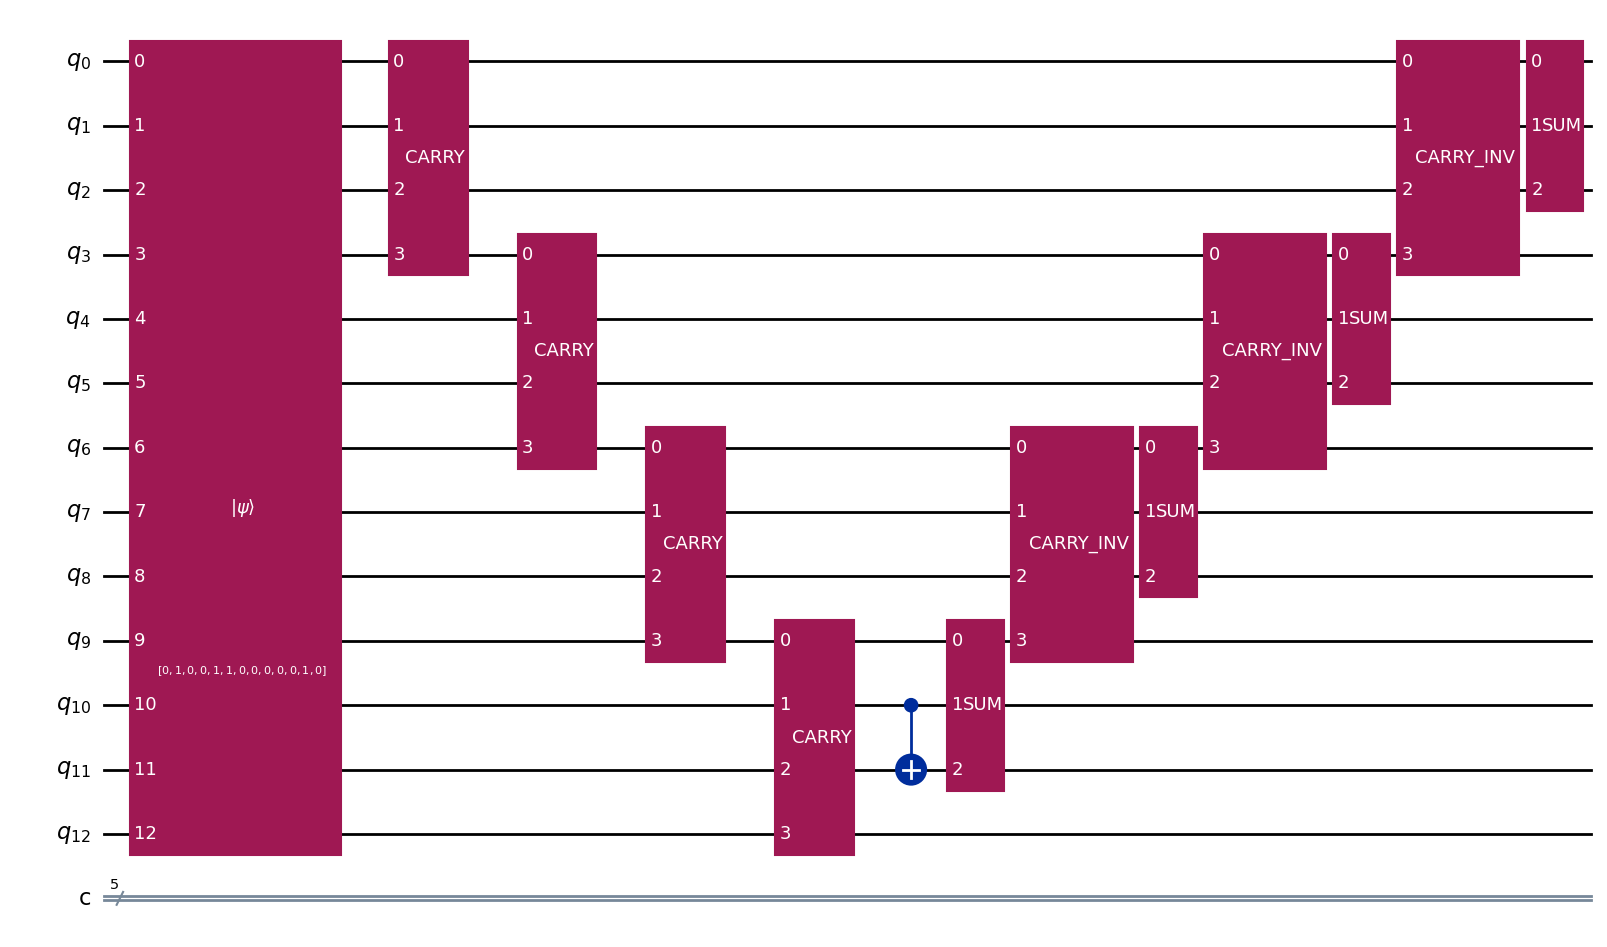

Value of a: 5
Value of b: 12
Bit length n = 4 

Expected result: 17
Integer result: 17
Correct? True 

Qubits Required for VBE Ripple Carry Adder: 3n + 1 = 13


In [3]:

def custom_VBER_ripple(a: int, b: int):
    """
    Function to perform addition using the VBE Ripple Carry Adder
    """

    sim = AerSimulator()

    # For checking purposes
    a_binary = np.binary_repr(a)
    b_binary = np.binary_repr(b)
    length_of_a = len(a_binary)
    length_of_b = len(b_binary)      

    # Pad the binary if they are not the same length string
    if (length_of_a>length_of_b):
        padding = "0" * np.abs(length_of_a - length_of_b)
        b_binary = padding + np.binary_repr(b)
    elif (length_of_a<length_of_b):
        padding = "0" * np.abs(length_of_b - length_of_a)
        a_binary = padding + np.binary_repr(a)

    # We need to assign each part of the binary representation to the correct register
    # That means splitting the strings and inserting the intermediate zeroes between digits
    binary_rep_array_a = [char for char in a_binary]
    binary_rep_array_b = [char for char in b_binary]

    # Here we add the corresponding digit from each place (grouping for qubit placement)
    initial_qubits = ""
    amount = len(binary_rep_array_a)
    counter = 0 # Used later when inverting the process
    for i in range(amount):

        # Assemble the initial state
        # We want it to look like 0 ... b3 a3 0 b2 a2 0 b1 a1 0 b0 a0 0
        place_from_right = amount - i - 1
        initial_qubits = binary_rep_array_b[place_from_right] + binary_rep_array_a[place_from_right] + "0" + initial_qubits # The zero is for the qubits in between
        counter += 1

    initial_qubits = "0" + initial_qubits # The final 0 on the last qubit completes the setup

    # Setting up the quantum circuit
    n = len(initial_qubits) # Number of qubits we need
    classical_bits = len(binary_rep_array_a) + 1 # Number of classical bits is size of input binary plus 1 for carry
    qc = QuantumCircuit(n, classical_bits)

    # Initialize the qubits to the constructed state
    qc.initialize(initial_qubits, qc.qubits)

    # Create the gates from what we made before
    SUM = SUM_GATE()
    CARRY = CARRY_GATE()
    CARRY_Inverse = CARRY_INVERSE()

    # Now we implement the gates constructed earlier
    # First the sequence of CARRY gates
    for i in range(counter):
        input_q0 = 3*i
        input_q1 = 1 + 3*i
        input_q2 = 2 + 3*i
        input_q3 = 3 + 3*i

        qargs = [input_q0, input_q1, input_q2, input_q3]
        qc.append(CARRY, qargs)

    # This CNOT gate uses the result of the sequence of CARRY gates to determine whether a carry bit is needed
    qc.cx(n-3, n-2)

    # The subsequent SUM and CARRY inverse gates 
    # We reuse the entries from above and work backwards
    for i in range(counter):
        # First gate is only sum with no inverse
        if (i == 0):
            qc.append(SUM, [input_q0, input_q1, input_q2])
        else:
            # Decreasing back to where we started
            input_q0 = 3*(counter - 1 - i) 
            input_q1 = 1 + 3*(counter - 1 - i)
            input_q2 = 2 + 3*(counter - 1 - i)
            input_q3 = 3 + 3*(counter - 1 - i)
            qargs = [input_q0, input_q1, input_q2, input_q3]
            qc.append(CARRY_Inverse, qargs)
            qc.append(SUM, qargs[:3])

    # Have a look at the complete circuit
    display(qc.draw("mpl"))


    # We must now reconstruct the binary result
    # Where b_i once occupied now s_i does, and we want the binary sn sn-1 ... s2 s1 s0 (where sn is the carry)
    # So we need to extract the state of every third qubit (2, 5, 8, 11, ... n-1)
    si = 2
    binary_bits = np.empty(classical_bits, dtype="int")
    binary_bits[0] = si
    for i in range(1, classical_bits-1):
        si += 3
        binary_bits[i] = si

    # Putting the carry at the end
    binary_bits[-1] = n-1

    #Reverse the array so it's in little endian ordering
    binary_bits = np.flip(binary_bits)

    # Classical bits to be measured to
    classical_array = [(classical_bits - i - 1) for i in range(classical_bits)]

    # Determining the outcome of addition
    # The state of each measured bit together gives the binary result of a + b
    qc.measure(binary_bits, classical_array)
    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    # There's only one possible state, hence one set of bits, hence one integer
    for bits in counts:
        integer_result = int(bits, 2)

    return integer_result, n, amount


# Using the circuit
a = 5
b = 12

output, qubits_needed, n = custom_VBER_ripple(a, b)

print("Value of a:", a)
print("Value of b:", b)
print("Bit length n =", n, "\n")
print("Expected result:", a + b)
print("Integer result:", output)
print("Correct?", a+b == output, "\n")
print("Qubits Required for VBE Ripple Carry Adder: 3n + 1 =", qubits_needed)


### The VBE Ripple Carry Adder (from Qiskit's Circuit Library)

The VBE Ripple Carry Adder may also be called from the existing library of circuits provided by Qiskit. The implementation is similar to the example provided above. For the rest of the notebook the circuits will be built using the Qiskit implementation to provide consistency across projects.

Documentation of the Qiskit VBE Ripple Carry Adder can be found here: https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.VBERippleCarryAdder

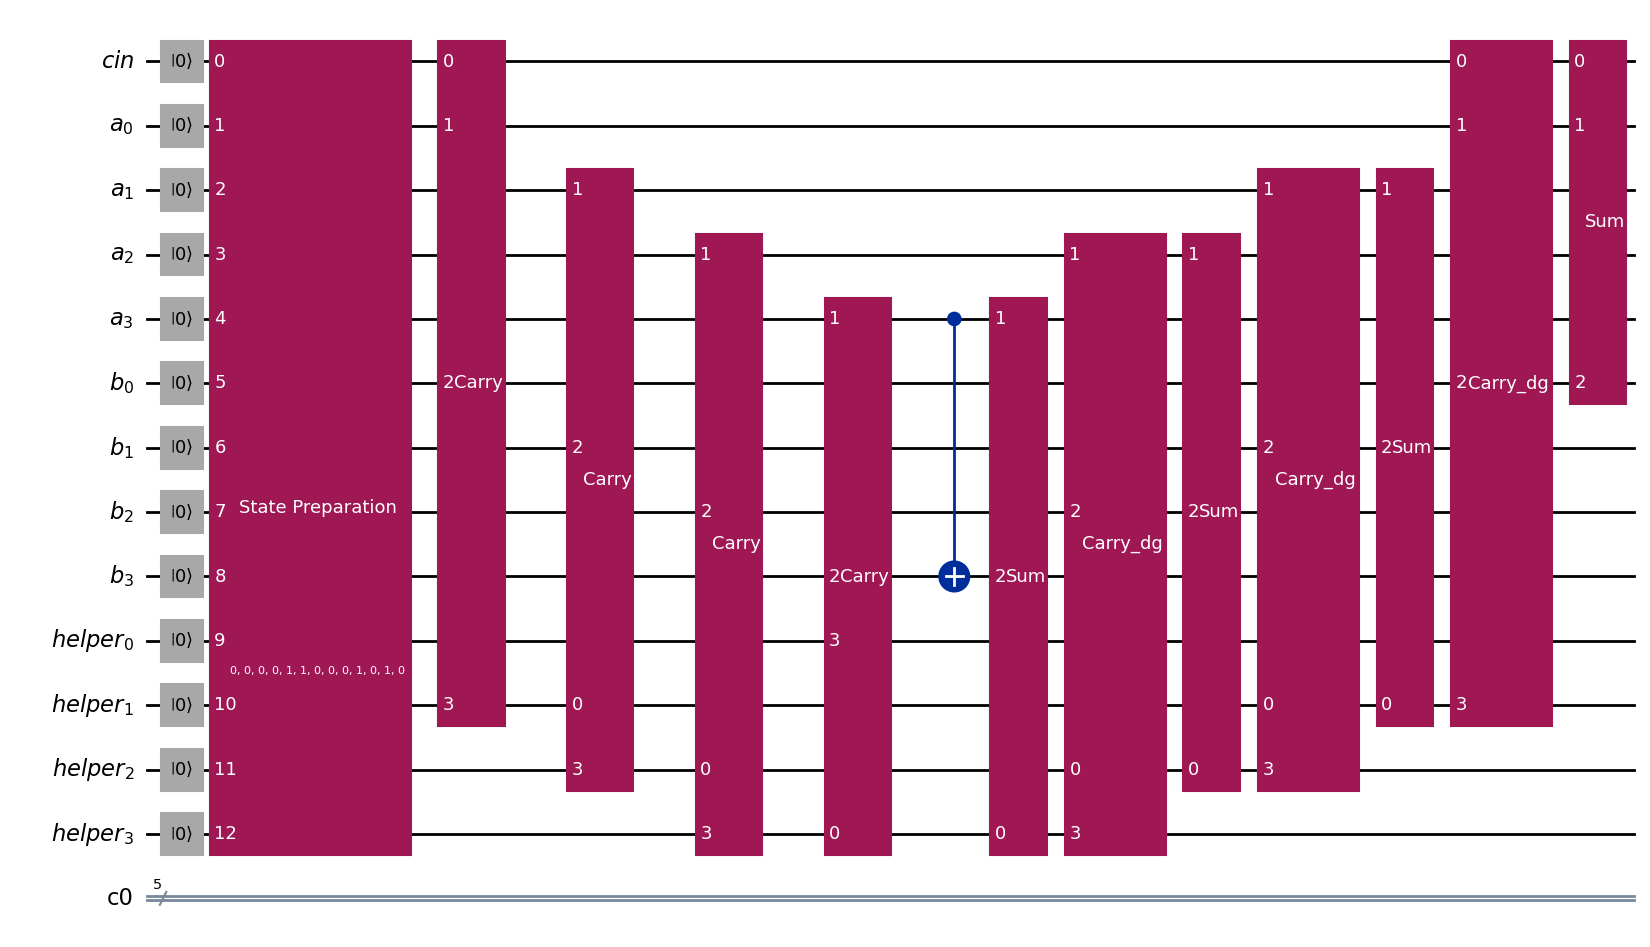

Value of a: 5
Value of b: 12
Bit length n = 4 

Expected result: 17
Integer result: 17
Correct? True 

Qubits Required for VBE Ripple Carry Adder: 3n + 1 = 13


In [4]:

def VBER_RIPPLE(a: int, b: int):
    """
    Function to perform binary addition using Qiskit's built in VBERippleCarryAdder
    """

    sim = AerSimulator()

    # For checking purposes
    a_binary = np.binary_repr(a)
    b_binary = np.binary_repr(b)
    length_of_a = len(a_binary)
    length_of_b = len(b_binary)      

    # Pad the binary if they are not the same length string
    if (length_of_a>length_of_b):
        padding = "0" * np.abs(length_of_a - length_of_b)
        b_binary = padding + np.binary_repr(b)
    elif (length_of_a<length_of_b):
        padding = "0" * np.abs(length_of_b - length_of_a)
        a_binary = padding + np.binary_repr(a)

    length_of_a = len(a_binary)
    length_of_b = len(b_binary)

    # The VBE requires a number of helper ancilla equal to the number of qubits needed to hold a single binary representation
    amount = len(a_binary)
    initial_qubits = ("0" * amount) + b_binary + a_binary + "0"

    # Setting up the quantum circuit
    n = len(initial_qubits)

    # Finding the registers where the result is stored and the number of classical bits needed to hold the result
    binary_bits = [amount+1+i for i in range(length_of_b+1)]
    classical_array = [i for i in range(amount+1)]

    # Create the circuit
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(length_of_a, "a")
    b_register = QuantumRegister(length_of_b, "b")
    helpers = QuantumRegister(amount, "helper")

    # The number of classical bits needed is size of b plus 1 for the carry
    classical_bit_reg = ClassicalRegister(length_of_b + 1)
    qc = QuantumCircuit(cin, a_register, b_register, helpers, classical_bit_reg)

    # Initialize the qubits to the constructed state
    qc.initialize(initial_qubits, qc.qubits)

    # Use Qiskit's VBERRippleCarryAdder
    VBER_circuit = VBERippleCarryAdder(amount, kind="full", name="VBER")
    circuit_with_adder = qc.compose(VBER_circuit)

    qubits_needed = len(initial_qubits)

    # Visualize the constituent parts
    circuit_with_adder = circuit_with_adder.decompose()
    display(circuit_with_adder.draw("mpl"))

    # Get the outcome of addition
    circuit_with_adder.measure(binary_bits, classical_array)
    counts = sim.run(transpile(circuit_with_adder, sim), shots=10).result().get_counts()

    for bits in counts:
        integer_result = int(bits, 2)

    return integer_result, qubits_needed, amount


# Use the circuit
a = 5
b = 12

output, qubits_needed, amount = VBER_RIPPLE(a, b)

print("Value of a:", a)
print("Value of b:", b)
print("Bit length n =", n, "\n")
print("Expected result:", a + b)
print("Integer result:", output)
print("Correct?", a+b == output, "\n")
print("Qubits Required for VBE Ripple Carry Adder: 3n + 1 =", qubits_needed)



### The VBE Modular Adder

We now use the VBE Ripple Carry Adder to construct a modular adder. Our goal is to find $a + b$ mod $N$ for integers $a, b, N$ with $a, b <N$


#### Explanation of Circuit

The circuit is divided into three sections. Note that the inverse of subtraction is addition, hence the inverse of the addition gate is a subtraction gate.

1. First the adder finds $a + b$, then the swap gates place N on the main register, and the inverse adder (subtraction) finds $a + b - N$

2. The behaviour of the second section changes depending on the result of $a + b - N$. If $a + b - N < 0$, then $a + b < N$. Hence we need only add $a$ and $b$ to find $a + b$ mod $N$. To do this, note that $a + b - N < 0$ means that the final digit of the register will be 1 (as a negative binary number). Thus the CNOT gate targeting the ancilla will not be activated. In turn none of the following CNOT gates will be activated either.

    This leads to a cascade of gates cancelling with their inverses: The addition gate in the second section cancels with its inverse from the first section, then the SWAP gates cancel each other (since SWAP is it's own inverse), and finally the inverse adder cancels with the inital adder. In effect, the circuit consists of a single adder gate which finds $a + b$ exactly as we wanted.

3. On the other hand, if $a + b - N \geq 0$, then $a + b \geq N$ In this case the final digit will be 0 and so the CNOT gate targeting the ancilla is activated. This results in N being temporarily removed from the first register and then put back. The swap gates then replace $a$ and $N$ back to their original registers. The subtraction gate then removes $a$ giving $b - N$, which will be negative since $b$ strictly less than $N$. As a result the final CNOT will reset the ancilla to 0. Lastly the addition gate adds $a$ again, giving us $a + b - N$.

Since $a < N$ and $b < N$, $a + b < 2N$, therfore $0 \leq a + b - N < N$. Thus we again have our desired result of $a + b$  mod $N$.


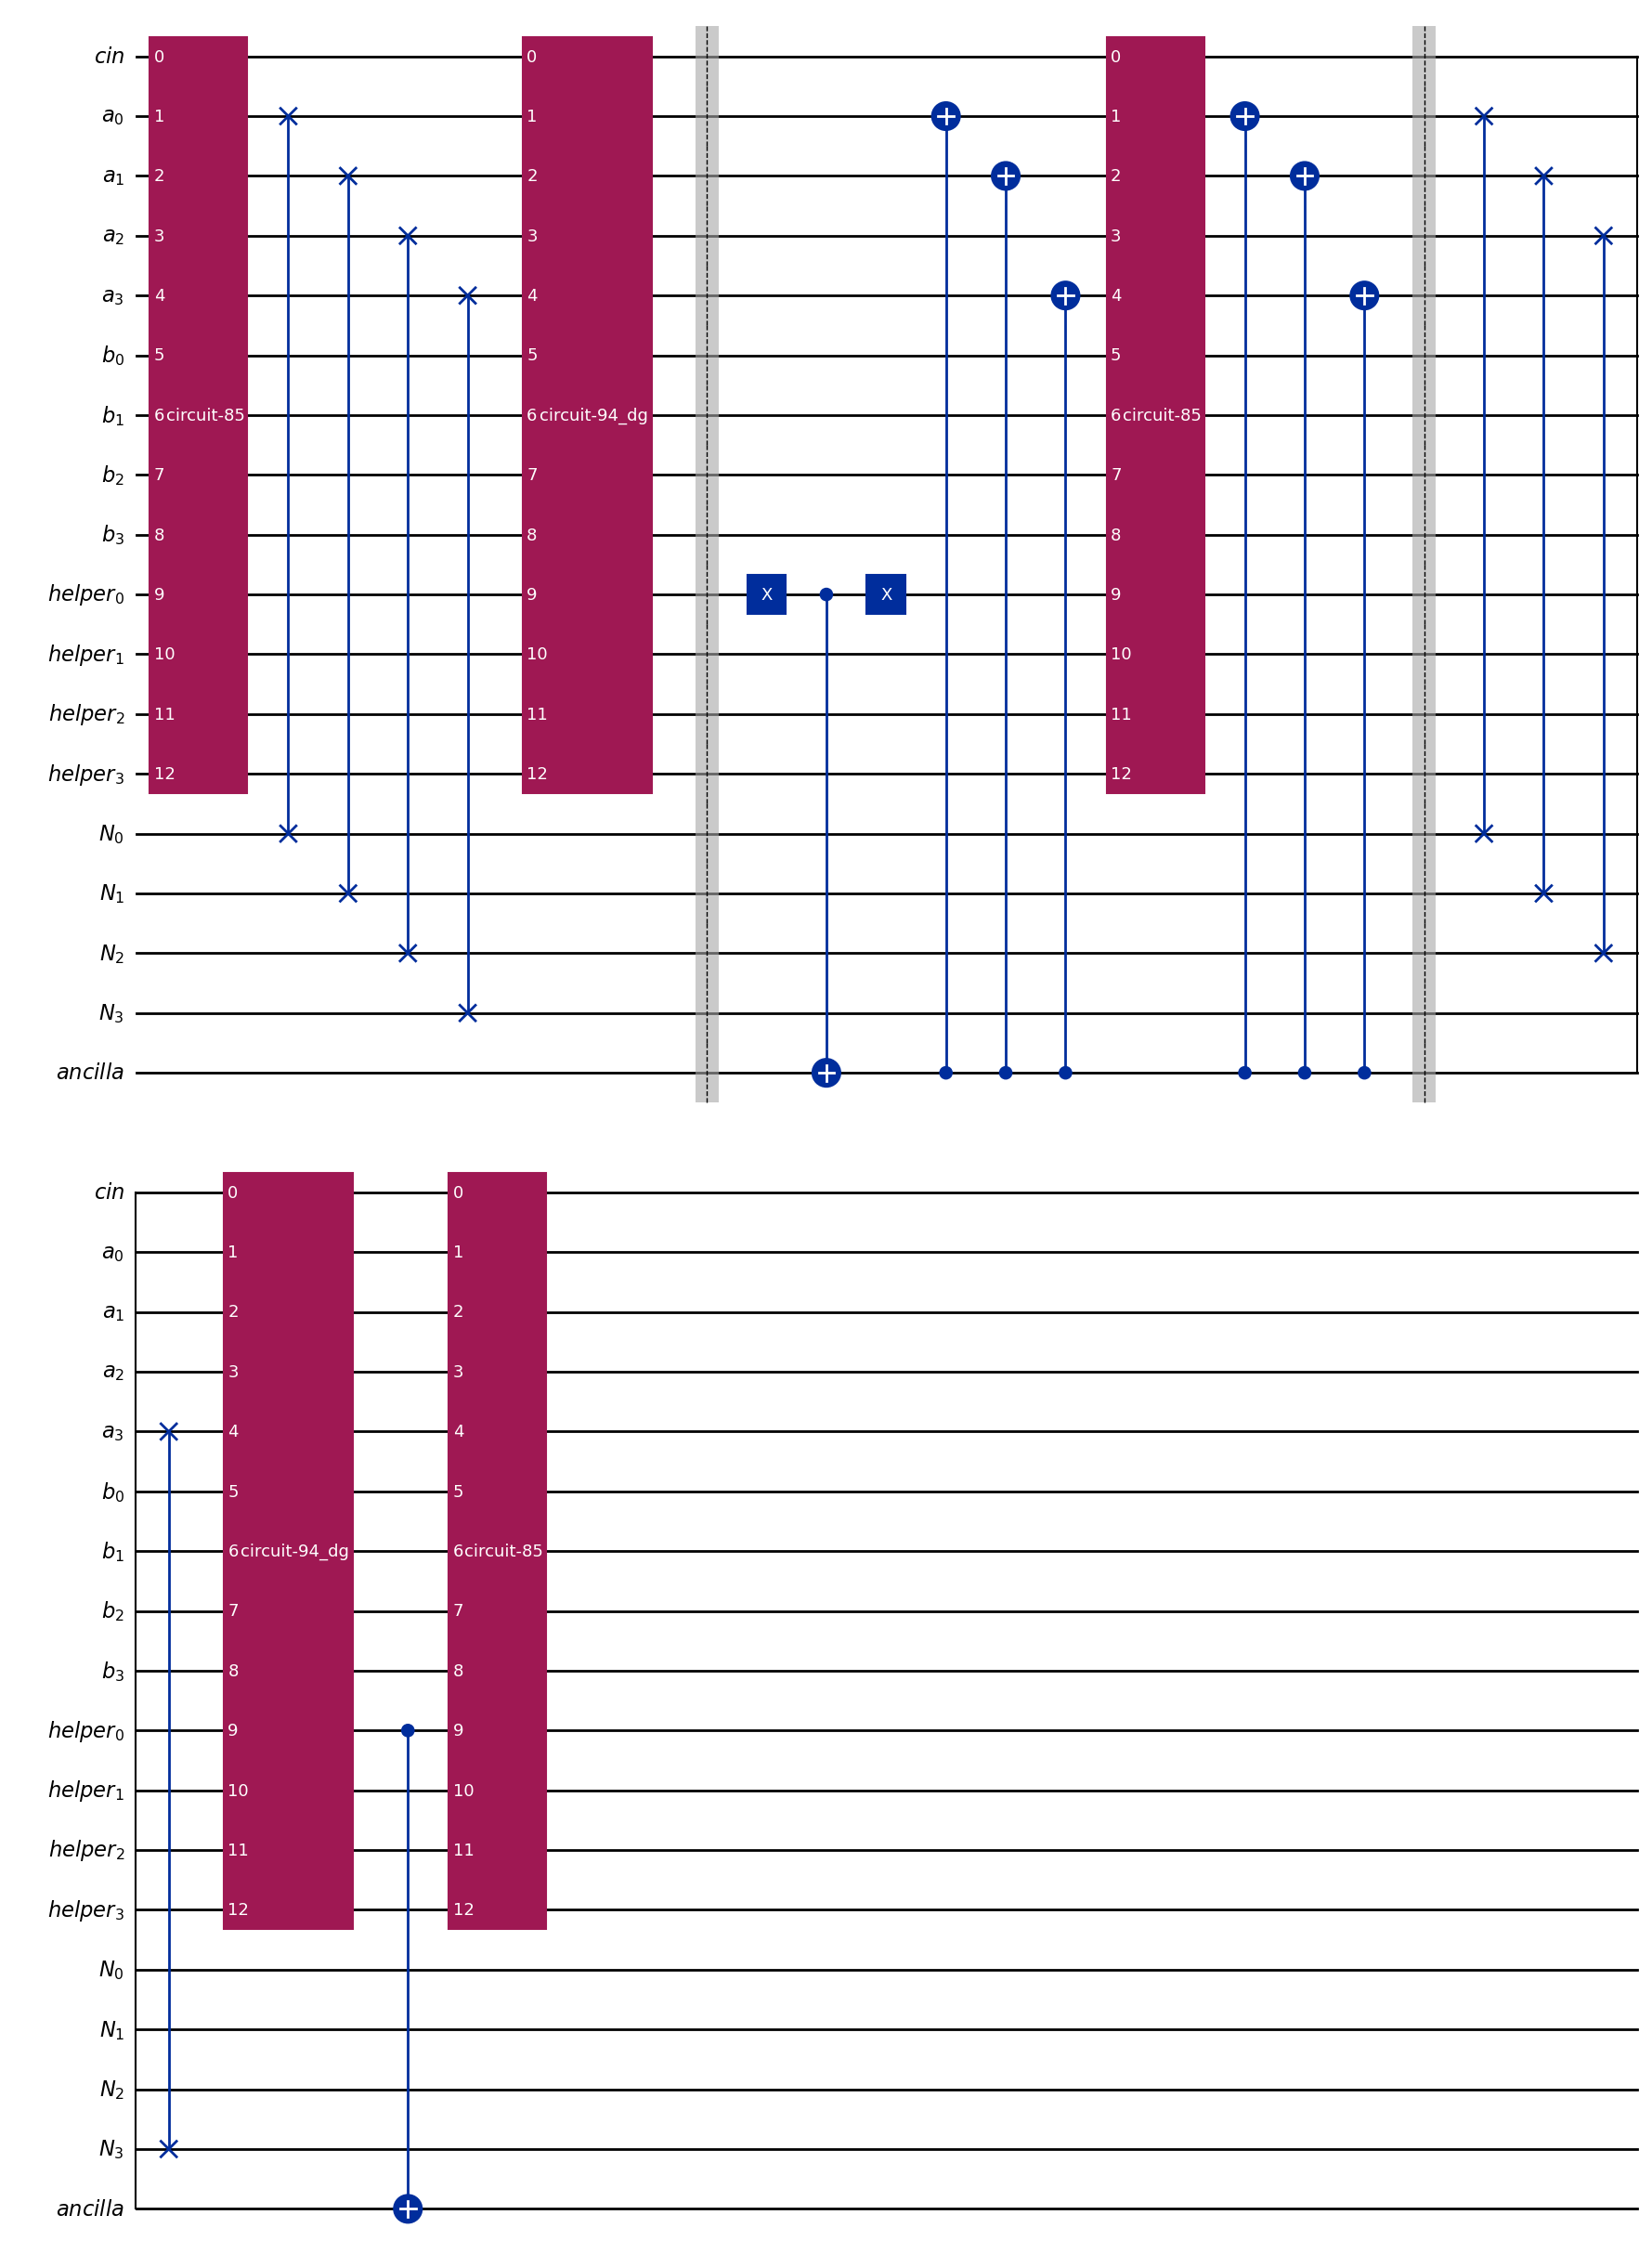

RESULT FOR CIRCUIT ABOVE

Value of a: 7
Value of b: 9
Value of N: 11

Bit length n = 4
Qubits Required for VBE Modular Adder: 2(2n + 1) = 18 

Expected result:  5
Calculated result: 5
Correct? True 

RESULT

Value of a: 5
Value of b: 12
Value of N: 17

Bit length n = 5
Qubits Required for VBE Modular Adder: 2(2n + 1) = 22 

Expected result:  0
Calculated result: 0
Correct? True 



In [5]:

def VBER_MODDADD(N: int, showcircuit = False):
    """Fucntion to create the VBE-based Modular Adder using the VBERippleCarryAdder"""

    N_binary = np.binary_repr(N)
    n = amount = len(N_binary)

    # Create the circuit
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(n, "a")
    b_register = QuantumRegister(n, "b")
    helpers = QuantumRegister(n, "helper")
    N_register = QuantumRegister(n, "N")
    ancilla = QuantumRegister(1, "ancilla") 

    qc = QuantumCircuit(cin, a_register, b_register, helpers, N_register, ancilla, name="VBE_MODADD")

    # Use Qiskit's VBERippleCarryAdder
    VBE = VBERippleCarryAdder(n, kind="full", name="VBE") #.decompose()
    VBE_inverse = VBERippleCarryAdder(n, kind="full", name="VBE").inverse()

    # Establishing the bits places of each number and how they are positioned on the circuit
    # cin = 0

    first_digit_of_a = 1
    last_digit_of_a = n
    # first_digit_of_b = n + 1
    # last_digit_of_b = 2*n

    c_out = 2*n + 1

    # first_digit_of_help = 2*n + 2
    # last_digit_of_help = 2*n + amount

    first_digit_of_N = 2*n + amount + 1
    # last_digit_of_N = 3*n + amount

    ancillary = 3*n + amount + 1

    # Step 1 is the Adder
    qc = qc.compose(VBE)

    # Step 2 is the SWAP for a and N
    for i in range(first_digit_of_a, last_digit_of_a+1):
        # Swapping the entries along original a with those along original N
        # The -1 is to accomodate that i starts at 1 (due to the ancilla)
        qc.swap(i, first_digit_of_N + i - 1)

    # Step 3 is the inverse adder (subtraction)
    qc = qc.compose(VBE_inverse)

    if (showcircuit == True):
        qc.barrier()

    # Step 4 is the 0-control output to flip the ancilla qubit if needed
    qc.x(c_out)
    qc.cx(c_out, ancillary)
    qc.x(c_out)

    # Step 5 is the cancellation of N if the ancilla is 1
    # We need to know which registers started in 1 so we can apply the cx gate
    N_digits_list = list(N_binary)
    N_digits_list.reverse() # reverse because indicies start from the right

    for index, value in enumerate(N_digits_list):
        # if there's a 1 we need to flip that index so that at the end all are 0
        if (value == "1"):
            qc.cx(ancillary, index + 1) # controlled by ancillary, flip the register where the "1" is

    # Step 6 is the Add gate again
    qc = qc.compose(VBE)

    # Step 7 we replace N on the initial register (if it was cancelled before)
    for index, value in enumerate(N_digits_list):
        # if there's a 1 we need to re-flip that index
        if (value == "1"):
            qc.cx(ancillary, index + 1) # controlled by ancillary, flip the register where the "1" is

    if (showcircuit == True):
        qc.barrier()

    # Step 8 we swap the registers back to what they were at the start
    for i in range(first_digit_of_a, last_digit_of_a+1):
        # Swapping the entries along original a with those along original N
        # The -1 is to accomodate that i starts at 1 (due to the ancilla)
        qc.swap(i, first_digit_of_N + i - 1)

    # Step 9 we subtract again
    qc = qc.compose(VBE_inverse)

    # Step 10, reset the ancillary
    qc.cx(c_out, ancillary)

    # Step 11 add N again
    qc = qc.compose(VBE)

    # Send circuit to instruction for later use
    vbe_moddadd = qc.to_instruction()  

    if (showcircuit == True):
        display(qc.draw("mpl"))

    return vbe_moddadd


def create_vbe_modadd_circuit(a: int, b: int, N: int, showcircuit = False):
    """Prepares a circuit and finds the result of a + b mod N using the VBE Modular Multiplier"""

    sim = AerSimulator()

    # For checking purposes
    a_binary = np.binary_repr(a)
    b_binary = np.binary_repr(b)
    N_binary = np.binary_repr(N)
    length_of_a = len(a_binary)
    length_of_b = len(b_binary)
    length_of_N = len(N_binary)      

    # Pad the binary if they are not the same length string
    padding = ""
    if (length_of_a < length_of_N):
        padding = "0" * (length_of_N - length_of_a)
        a_binary = padding + a_binary
    if (length_of_b < length_of_N):
        padding = "0" * (length_of_N - length_of_b)
        b_binary = padding + b_binary

    length_of_a = len(a_binary)
    length_of_b = len(b_binary) # Now equal to length of N_binary for consitency

    amount = len(N_binary) # helper qubits needed by the VBERippleCarryAdder
    initial_state = "0" + N_binary + ("0" * (amount - 1)) + "0" + b_binary + a_binary + "0"

    qubits_needed = len(initial_state)
    classical_bits_needed = len(b_binary) # Output is on the register where b started

    # Create the circuit
    qc = QuantumCircuit(qubits_needed, classical_bits_needed)
    qc.initialize(initial_state, qc.qubits)

    n = len(N_binary)

    # Use the circuit we prepared above
    my_vbe_modadd = VBER_MODDADD(N, showcircuit)
    qc = qc.compose(my_vbe_modadd, qc.qubits)


    # Measure the register where the result is stored
    binary_bits = list(range(n + 1, 2*n + 1))
    classical_bits = list(range(classical_bits_needed))
    qc.measure(binary_bits, classical_bits)

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    # Show results of analysis
    for bits in counts:

        if (showcircuit == True):
            print("RESULT FOR CIRCUIT ABOVE\n")
        else:
            print("RESULT\n")

        print("Value of a:", a)
        print("Value of b:", b)
        print("Value of N:", N)
            
        print("\nBit length n =", n)
        print(f"Qubits Required for VBE Modular Adder: 2(2n + 1) = {qubits_needed} \n")

        expected = np.mod(a+b, N)
        print("Expected result: ", expected)

        integer_result = int(bits, 2)
        print(f"Calculated result: {integer_result}")
        print("Correct?", integer_result == expected, "\n")

# Use the circuit
a = 7
b = 9
N = 11

create_vbe_modadd_circuit(a, b, N, showcircuit=True)

create_vbe_modadd_circuit(5, 12, 17)



### The VBE Modular Multiplier

The Modular Multiplier works by breaking multiplication down into a series of additions. The goal is to calculate $ax$ mod $N$.
We define the modular exponentiator circuit in the final section.

The binary representation of the number $x$ is given as $x_{n-1} \ x_{n-2} \ \dots \ x_1 \ x_0$.
The expansion of $x$ in base 2 is:
$$x = x_0 \cdot (2^0) + x_1 \cdot (2^1) + \dots + x_{n-2} \cdot (2^{n-2}) + x_{n-1} \cdot (2^{n-1})$$

When we multiply $x$ by a scalar `a`, the equation is:
$$ax = x_0(a \cdot 2^0) + x_1(a \cdot 2^1) + \dots + x_{n-2}(a \cdot 2^{n-2}) + x_{n-1}(a \cdot 2^{n-1})$$

We want to calculate $ax$ mod $N$. This is equivalent to the sum (mod $N$) of the terms $x_i(a2^i)$ for all digits $x_i$ which are set to $1$ in binary. Let $C_i = a2^i$. To find the desired sum, we use gates controlled by the binary digits of x to put $C_i$ on the addition register. If $x_i = 1$, $C_i$ is added using the Modular Adder from the previous section to ensure the sum remains mod $N$. Repeating this process across all digits of x results in $ax$ mod $N$.

The circuit also includes an overall control register. If not activated, this register will set the result to the binary value of $x$ itself. This feature is useful for the next section when we must use several controlled Modular Multiplier gates to create the Modular Exponentiator.


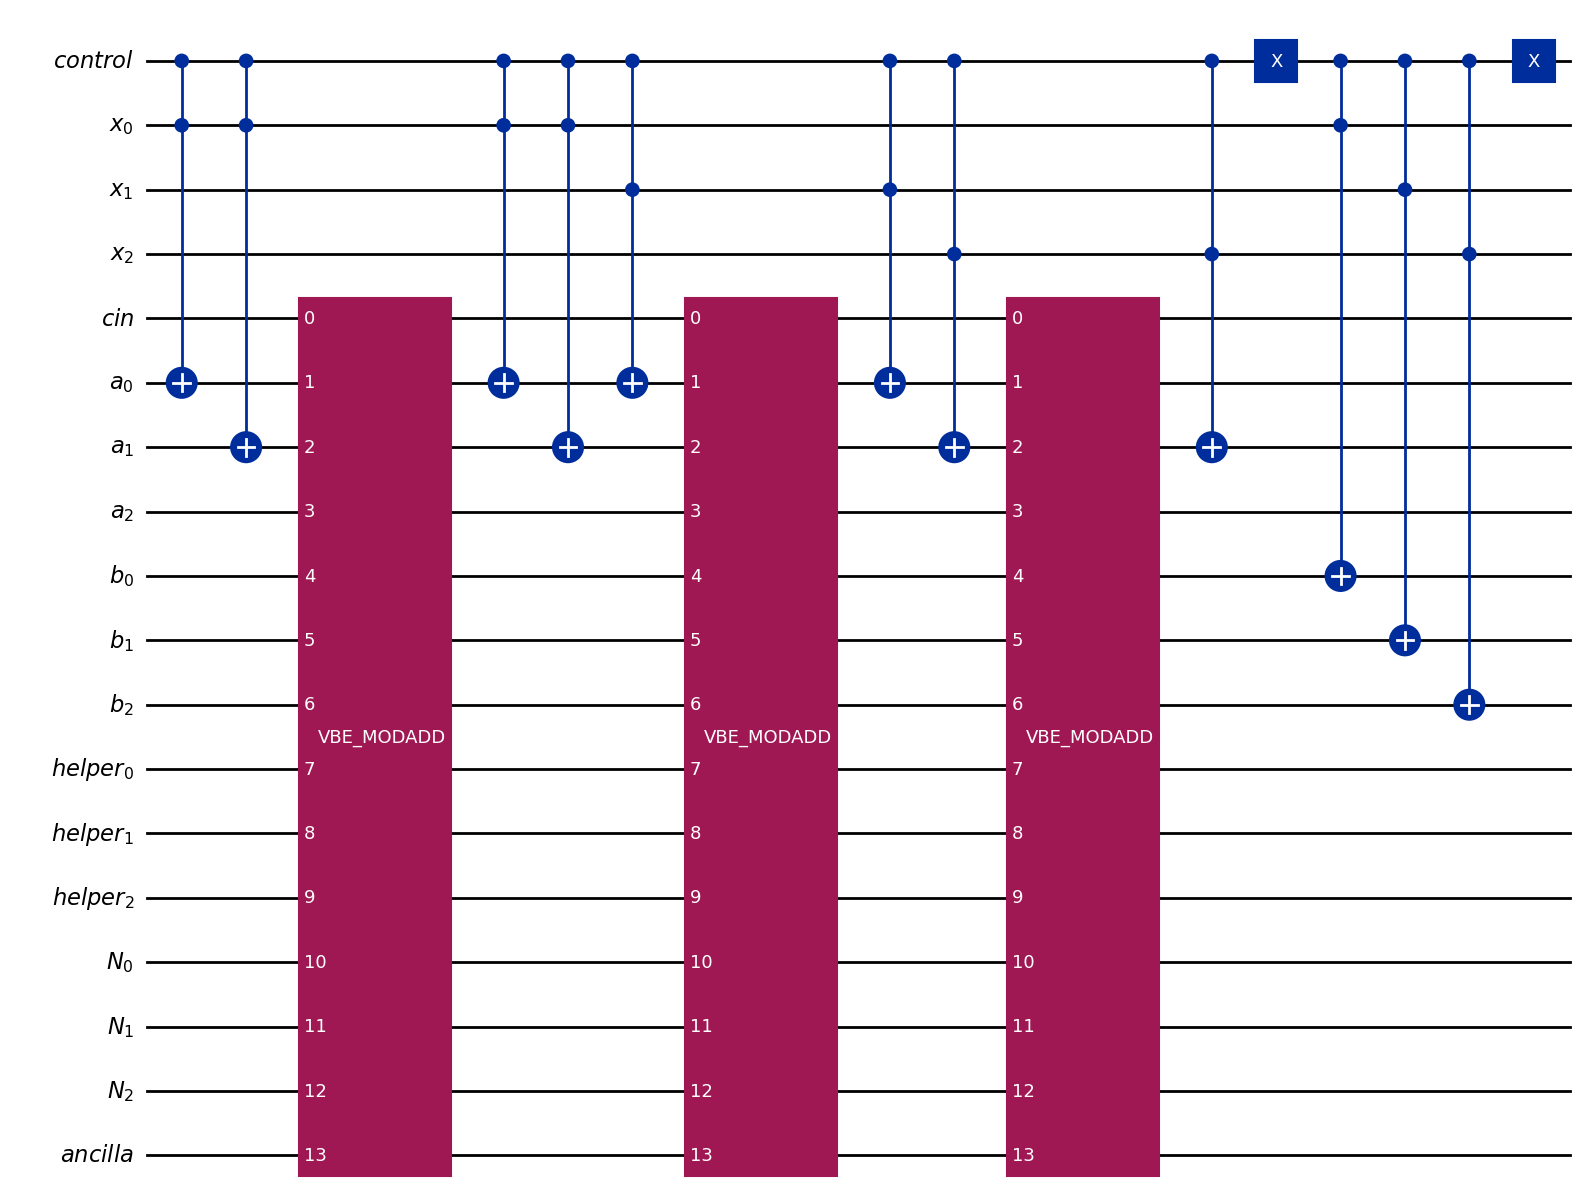

RESULT FOR CIRCUIT ABOVE

Value of a: 3
Value of x: 2
Value of N: 5

Bit length n = 3
Qubits Required for VBE Modular Multiplier: 5*n + 3 = 18 

Expected result:  1
Calculated result: 1
Correct? True 

RESULT

Value of a: 7
Value of x: 3
Value of N: 15

Bit length n = 4
Qubits Required for VBE Modular Multiplier: 5*n + 3 = 23 

Expected result:  6
Calculated result: 6
Correct? True 



In [6]:
def VBE_MODMULT(a, N, showcircuit = False):
    """Function to create the Modular Multiplier Gate using the VBE Modular Adder"""

    N_binary = np.binary_repr(N)
    n = amount = len(N_binary)

    # Finding the constants to pass to the circuit
    constants_array = [0*k for k in range(n)] # init empty array of correct size.

    # Calcualtion of each Ci
    for i in range(n):
        # In one step we calculate a(2^i) mod N
        constant_modded = np.mod(a*(2**i), N)
        constant_binary = np.binary_repr(constant_modded)
        constants_array[i] = constant_binary

    # Create the circuit
    control = QuantumRegister(1, "control")
    x_register = QuantumRegister(n, "x")
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(n, "a")
    b_register = QuantumRegister(n, "b")
    helpers = QuantumRegister(n, "helper")
    N_register = QuantumRegister(n, "N")
    ancilla = QuantumRegister(1, "ancilla") 

    qc = QuantumCircuit(control, x_register, cin, a_register, b_register, helpers, N_register, ancilla, name="VBE_MODMULT")

    # Here we identify where each part of the circuit begins

    c_control = 0

    # start_of_x = 1
    # end_of_x = n

    pseudo_cin = n + 1

    start_of_pseudo_a = n + 2
    # end_of_pseudo_a = 2*n + 1

    start_of_pseudo_b = 2*n + 2
    # end_of_pseudo_b = 3*n + 1

    # pseudo_cout = 3*n + 2

    # start_of_pseudo_help = 3*n + 3
    # end_of_pseudo_help = 3*n + 2 + (amount - 1)

    # start_of_N = 3*n + 3 + (amount - 1)
    # end_of_N = 4*n + 2 + (amount - 1)

    helper = 4*n + 3 + (amount - 1)

    # Here we perform the task of assigning the Ci's to the "a" register to be added
    moddadd_register_qubits = [j for j in range(pseudo_cin, helper + 1)]
    vbe_moddadd_gate = VBER_MODDADD(N)
    for i, binary in enumerate(constants_array):
        
        # We want to use xi as a control for the Ci element: if xi = 0 nothing happens
        x_i = 1 + i

        # List of the 1's and 0's in the binary representation of Ci mod N
        # Reversed for clarity of gate additions
        digits = list(binary)
        qubit_order_digits = digits[::-1]

        # Look at each element in the binary rep
        # If it's 1 we need to flip the corresponding register on pseudo a
        # When done for every 1, this creates Ci mod N on the pseudo a register
        for k in range(len(qubit_order_digits)):
            if (qubit_order_digits[k] == "1"):
                qc.ccx(0, x_i, start_of_pseudo_a + k) # correct register is a, uptick as we go

        # Perform the modular addition
        qc.append(vbe_moddadd_gate, moddadd_register_qubits)

        # Then we refresh the register to 0 for the next potetnial Cin
        for k in range(len(qubit_order_digits)):
            if (qubit_order_digits[k] == "1"):
                qc.ccx(0, x_i, start_of_pseudo_a + k) # correct register is a, uptick as we go


    # Eventually we will want the ability to control the whole circuit
    # If the control is zero we want to assign the starting x value to the end
    # We accomplish this here
    qc.x(c_control)
    for i in range(n):
        x_i = 1 + i
        qc.ccx(c_control, x_i, start_of_pseudo_b + i)
    qc.x(c_control)

    # Send circuit to instruction for later use
    vbe_moddmult = qc.to_instruction()

    if (showcircuit == True):
        display(qc.draw("mpl"))

    return vbe_moddmult


def create_vbe_modmult_circuit(a, x, N, showcircuit = False):
    """Prepares the circuit and finds the result of ax mod N using the VBE Modular Multiplier"""

    # Choose backend
    sim = AerSimulator()

    # For checking purposes
    x_binary = np.binary_repr(x)
    N_binary = np.binary_repr(N)
    length_of_x = len(x_binary)
    length_of_N = len(N_binary)

    n = length_of_N      

    # Pad the binary if they are not the same length string
    padding = ""
    if (length_of_x < length_of_N):
        padding = "0" * (length_of_N - length_of_x)
        x_binary = padding + x_binary

    length_of_x = len(x_binary)

    # Finding the constants to pass to the circuit
    constants_array = [0*k for k in range(n)] # init empty array of correct size.

    # Calcualtion of each Ci
    for i in range(n):
        # In one step we calculate Ci mod N
        constant_modded = np.mod( a*(2**i), N )
        constant_binary = np.binary_repr( constant_modded )
        constants_array[i] = constant_binary

    # Recall that VBE registers are of the form: "0" + N_binary + ("0" * (amount - 1)) + "0" + b_binary + a_binary + "0"
    amount = length_of_N
    qubits_needed = ( 3*n + 3 + (amount - 1) ) + n + 1 # VBE registers, plus x, plus c

    classical_bits_needed = n

    qc = QuantumCircuit(qubits_needed, classical_bits_needed)

    # Here we identify where the results are
    start_of_pseudo_b = 2*n + 2
    end_of_pseudo_b = 3*n + 1

    # Initialize qubits q2 to qn+1 to x
    # Note the "1" is to initialize the c_control to 1 so the modular addition works 
    empty_helpers_b_a_and_controls = ("0" * (amount - 1) ) + ( "0" * (2*n + 2) ) # (helpers) + (empty a and b and controls)
    initial_state =  "0" + N_binary + empty_helpers_b_a_and_controls + x_binary + "1"
    qc.initialize(initial_state, qc.qubits) 

    # Use the gate we constructed above to find the result
    my_vbe_modmult = VBE_MODMULT(a, N, showcircuit)
    qc = qc.compose(my_vbe_modmult, qc.qubits)

    # Measuring the result stored on teh pseudo b register
    binary_bits = list(range(start_of_pseudo_b, end_of_pseudo_b + 1))
    classical_bits = list(range(classical_bits_needed))
    qc.measure(binary_bits, classical_bits)

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    # Show the results of analysis
    for bits in counts:

        if (showcircuit == True):
            print("RESULT FOR CIRCUIT ABOVE\n")
        else:
            print("RESULT\n")

        print("Value of a:", a)
        print("Value of x:", x)
        print("Value of N:", N)
            
        print("\nBit length n =", n)
        print(f"Qubits Required for VBE Modular Multiplier: 5*n + 3 = {qubits_needed} \n")

        expected = np.mod(a*x, N)
        print("Expected result: ", expected)

        integer_result = int(bits, 2)
        print(f"Calculated result: {integer_result}")
        print("Correct?", integer_result == expected, "\n")


a = 3
x = 2
N = 5

create_vbe_modmult_circuit(a, x, N, True)

create_vbe_modmult_circuit(7, 3, 15)

### The VBE Modular Exponentiator

The Modular Exponentiator works by breaking multiplication down into a series of additions. The goal is to calculate $a^x$ mod $N$.

The binary representation of the number $x$ is given as $x_{n-1} \ x_{n-2} \ \dots \ x_1 \ x_0$.
The expansion of $x$ in base 2 is:
$$x = x_0 \cdot (2^0) + x_1 \cdot (2^1) + \dots + x_{n-2} \cdot (2^{n-2}) + x_{n-1} \cdot (2^{n-1})$$

Therefore
$$ a^x = a^{x_0 \cdot (2^0) + x_1 \cdot (2^1) + \dots + x_{n-2} \cdot (2^{n-2}) + x_{n-1} \cdot (2^{n-1})}$$

Which in turn becomes
$$a^{x_0 \cdot (2^0)}a^{x_1 \cdot (2^1)} \dots a^{x_{n-2} \cdot (2^{n-2})} a^{x_{n-1} \cdot (2^{n-1})} $$

Which is just a sequence of multiplications. Using the Modular Multiplier repeatedly will find us this product mod $N$, and therefore find $a^x$ mod $N$ as desired

One key detail of the circuit is the use of inverses. We need these to reset the accumulation register for re-use. As such, we not only have to invert the Modular Multiplier gate, but the values we must pass are the *inverse* of those just passed. 

For example, say $A_i = a^{2^i}$. If we passed $A_i$ mod N to the Modular Multiplier, we must pass $A_{i}^{-1}$ mod $N$ to the Inverse Modular Multiplier. In particular this means $a$ and $N$ cannot be arbitrary; they must be chosen so that inverses exist. This is equivalent to saying that we require GCD($a, N$) = 1.

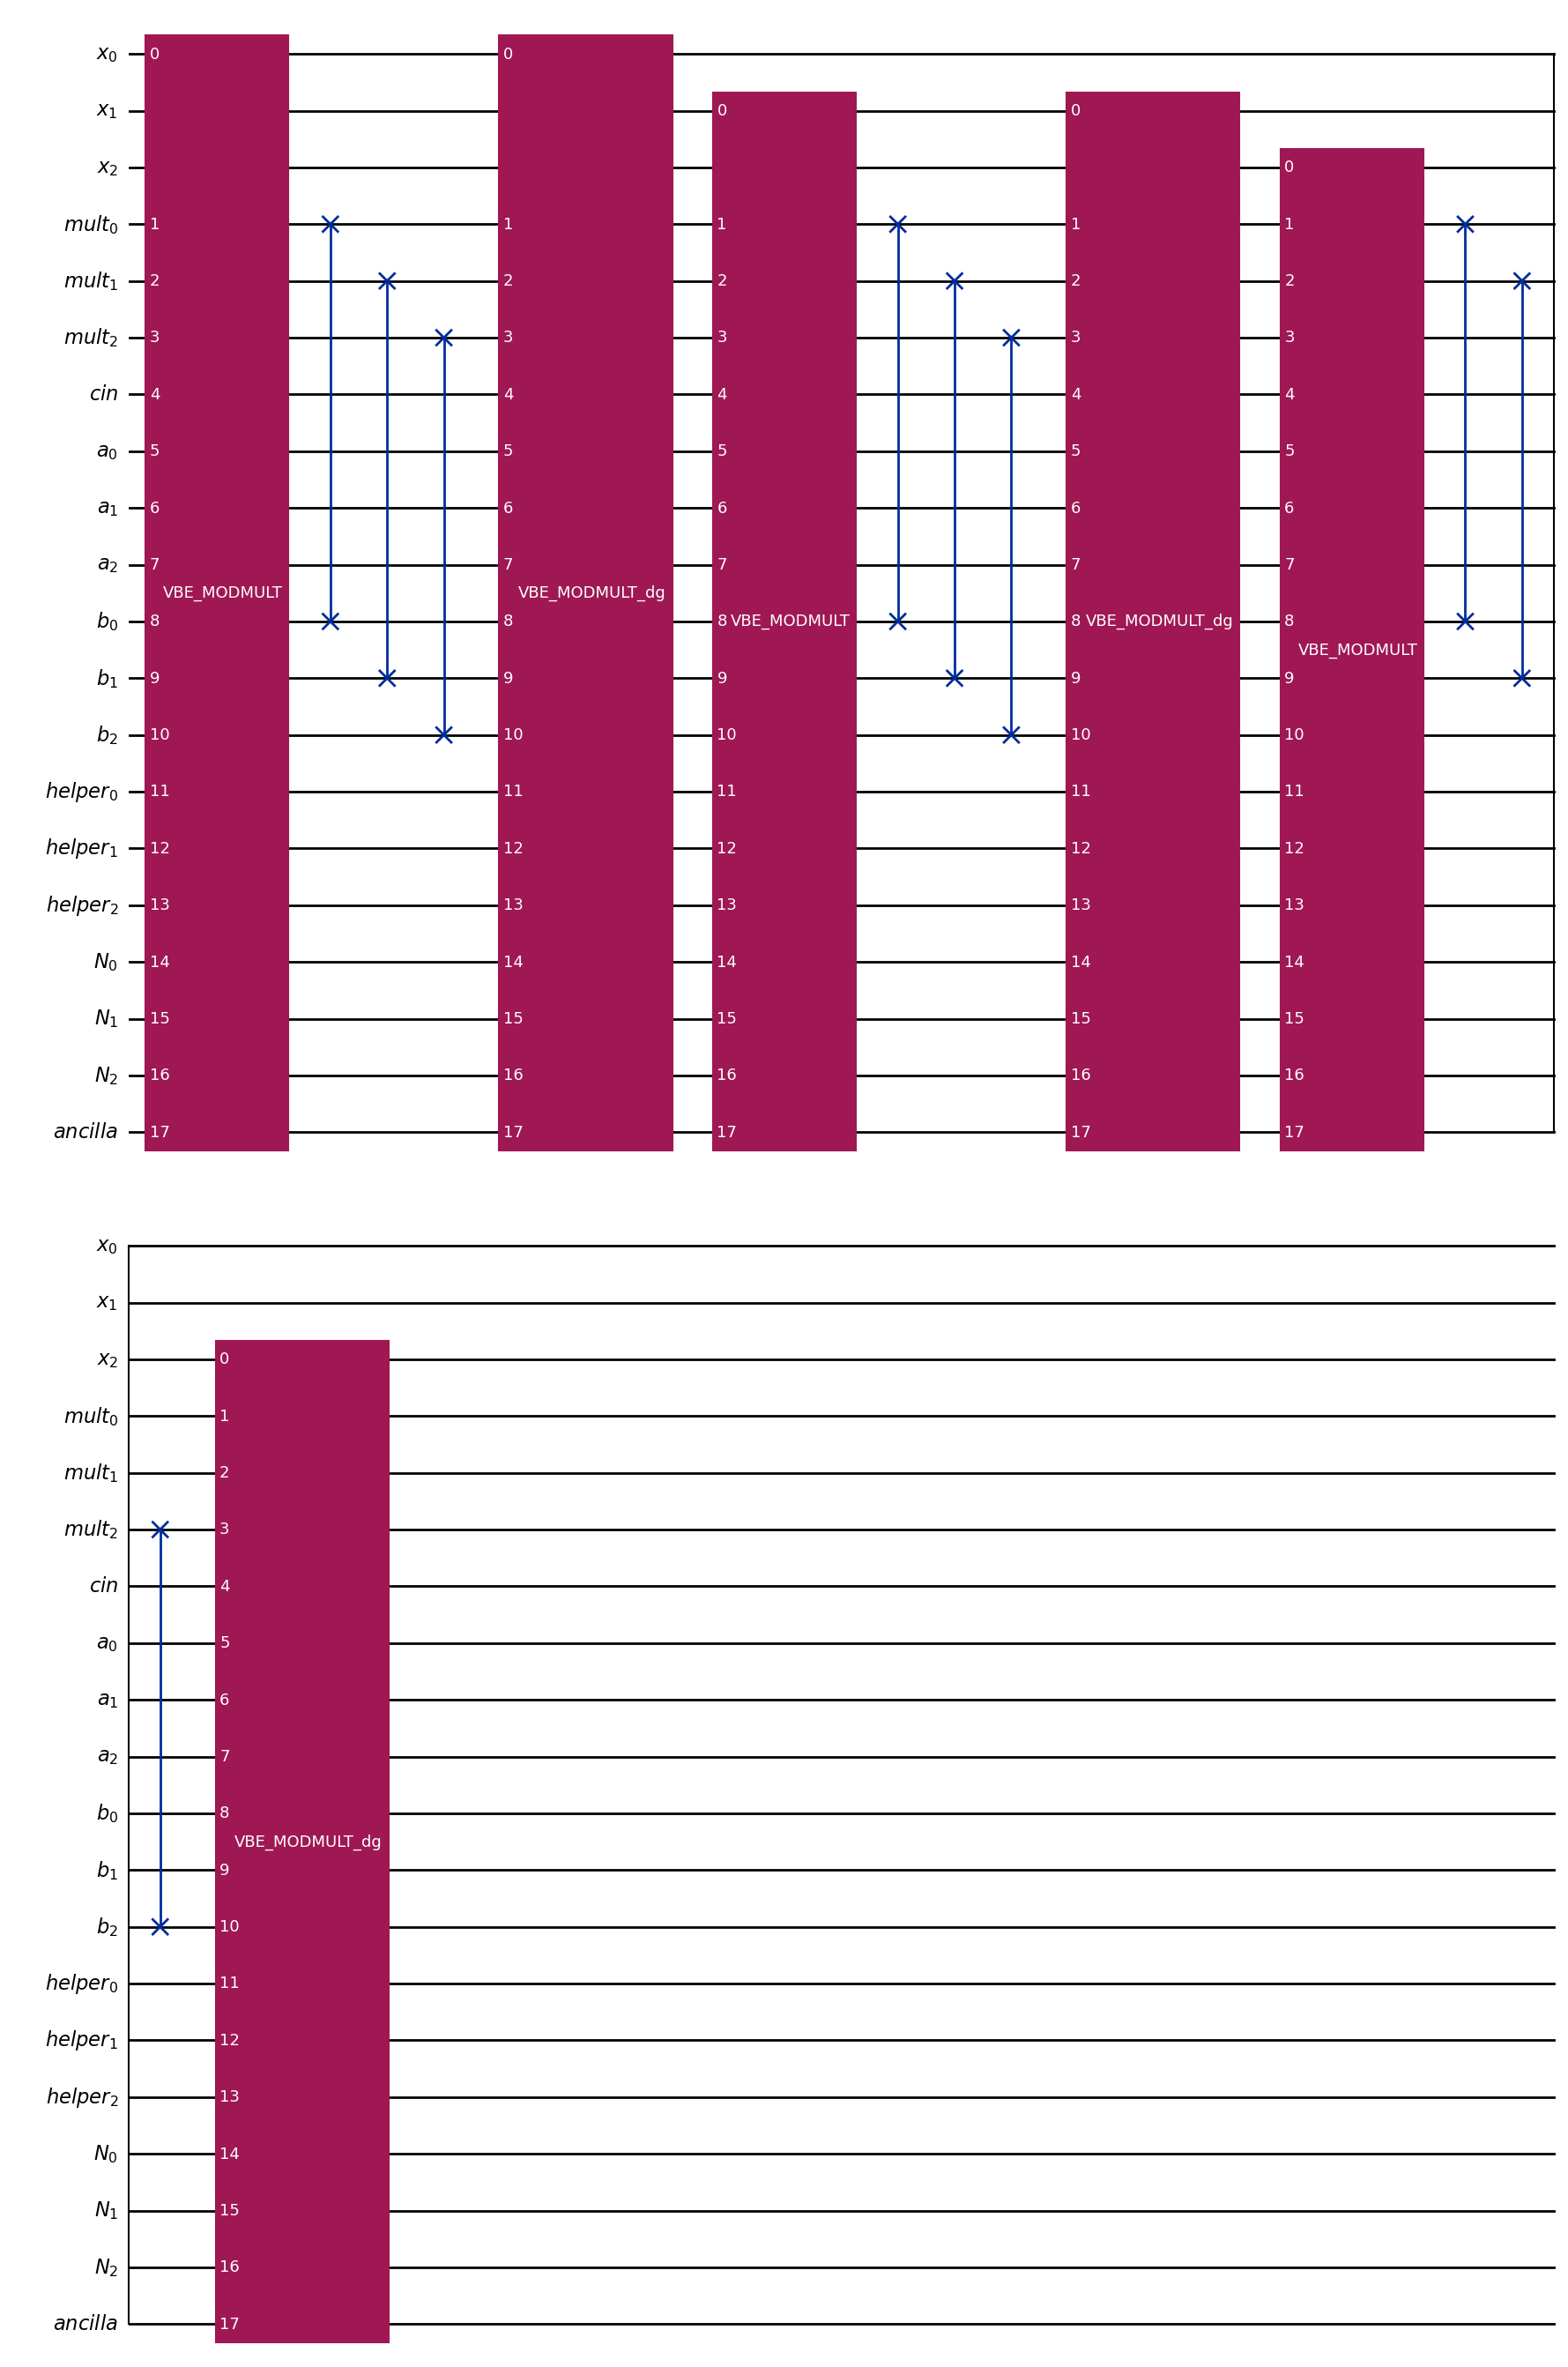

RESULT FOR CIRCUIT ABOVE

Value of a: 3
Value of x: 2
Value of N: 5

Bit length n = 3
Qubits Required for VBE Modular Exponentiator: 2(3*n + 1) = 20 

Expected result:  4
Calculated result: 4
Correct? True 

RESULT

Value of a: 3
Value of x: 4
Value of N: 7

Bit length n = 3
Qubits Required for VBE Modular Exponentiator: 2(3*n + 1) = 20 

Expected result:  4
Calculated result: 4
Correct? True 



In [7]:

def VBE_MODEXP(a, N, showcircuit = False):
    """Creates a Modular Exponentiation Gate based on the VBE Modular Multiplier"""

    N_binary = np.binary_repr(N)
    n = amount = len(N_binary)

    # Create the circuit
    control = QuantumRegister(n, "x")
    x_register = QuantumRegister(n, "mult")
    cin = QuantumRegister(1, "cin")
    a_register = QuantumRegister(n, "a")
    b_register = QuantumRegister(n, "b")
    helpers = QuantumRegister(n, "helper")
    N_register = QuantumRegister(n, "N")
    ancilla = QuantumRegister(1, "ancilla") 

    qc = QuantumCircuit(control, x_register, cin, a_register, b_register, helpers, N_register, ancilla, name="VBE_MODEXP")

    # Here we identify where each part of the circuit begins
    # start_of_x = 0
    # end_of_x = n - 1

    start_of_x_for_mult = n
    # end_of_x_for_mult = 2*n -1

    # pseudo_cin = 2*n

    # start_of_pseudo_a = 2*n + 1
    # end_of_pseudo_a = 3*n

    start_of_pseudo_b = 3*n + 1
    # end_of_pseudo_b = 4*n

    # pseudo_cout = 4*n + 1

    # start_of_pseudo_help = 4*n + 2
    # end_of_pseudo_help = 4*n + 1 + (amount - 1)

    # start_of_N = 4*n + 2 + (amount - 1)
    # end_of_N = 5*n + 1 + (amount - 1)

    helper = 5*n + 2 + (amount - 1)

    # Here we calculate the constants to be passed to the Modular Multiplier gates
    capital_As = []
    for i in range(n):
        Ai = int(np.mod(a**2**i, N))
        capital_As.append(Ai)


    # Implementing the VBE Modular Multiplier gates (and inverses) created earlier
    modmult_qubits = [q for q in range(start_of_x_for_mult, helper + 1)]
    for i in range(n):

        # Control plus qubits used by the gate
        qargs = [i] + modmult_qubits

        # Constant to pass
        A_i = capital_As[i]

        # Add the gate
        CMODMULT = VBE_MODMULT(A_i, N) #.control()
        qc.append(CMODMULT, qargs)

        # Swapping registers
        for k in range(n):
            qc.swap(start_of_x_for_mult + k, start_of_pseudo_b + k)

        # Implement iverse to reset accumulation register
        # Observe we use the inverse gate and also pass the inverse of A_i mod N
        CMODMULT_inverse = VBE_MODMULT(pow(A_i, -1, N), N).inverse()
        qc.append(CMODMULT_inverse, qargs)

    # Send circuit to instruction for later use
    modvbe_circuit = qc.to_instruction()

    if (showcircuit == True):
        display(qc.draw("mpl"))

    return modvbe_circuit

def create_vbe_modexp_circuit(a, x, N, showcircuit = False):
    """Prepares the circuit and finds the result of a^x mod N using the VBE Modular Exponentiator"""

    # Choose backend
    sim = AerSimulator()

    # For checking purposes
    x_binary = np.binary_repr(x)
    N_binary = np.binary_repr(N)
    length_of_x = len(x_binary)
    length_of_N = len(N_binary)

    n = length_of_N 

    # Pad the binary if they are not the same length string
    padding = ""
    if (length_of_x < length_of_N):
        padding = "0" * (length_of_N - length_of_x)
        x_binary = padding + x_binary

    length_of_x = len(x_binary)

    # Create the circuit
    amount = n
    qubits_needed = ( ( 3*n + 3 + (amount - 1) ) + n ) + n # VBE_MMODMULT registers, minus the generic control, plus x (which becomes the control)
    classical_bits_needed = n
    qc = QuantumCircuit(qubits_needed, classical_bits_needed)

    # Here we identify where the result is stored

    start_of_x_for_mult = n
    end_of_x_for_mult = 2*n - 1

    # Creating the initial state
    initial_x_for_mult_register = "0" * (n - 1) + "1" # Starts as ...0001
    initial_pseudo_a_register = "0" * n
    initial_pseudo_b_register = "0" * n

    helper_0s = "0" * (amount - 1)

    initial_state = "0" + N_binary + helper_0s + "0" + initial_pseudo_b_register + initial_pseudo_a_register + "0" + initial_x_for_mult_register + x_binary

    qc.initialize(initial_state, qc.qubits)

    # Use the gate we created earlier
    my_vbe_modexp = VBE_MODEXP(a, N, showcircuit)
    qc = qc.compose(my_vbe_modexp, qc.qubits)

    # Measure the register where the result is stored
    binary_bits = list(range(start_of_x_for_mult, end_of_x_for_mult + 1))
    classical_bits = list(range(classical_bits_needed))
    qc.measure(binary_bits, classical_bits)

    counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()

    # Show the results of analysis
    for bits in counts:

        if (showcircuit == True):
            print("RESULT FOR CIRCUIT ABOVE\n")
        else:
            print("RESULT\n")

        print("Value of a:", a)
        print("Value of x:", x)
        print("Value of N:", N)
            
        print("\nBit length n =", n)
        print(f"Qubits Required for VBE Modular Exponentiator: 2(3*n + 1) = {qubits_needed} \n")

        expected = np.mod(a**x, N)
        print("Expected result: ", expected)

        integer_result = int(bits, 2)
        print(f"Calculated result: {integer_result}")
        print("Correct?", integer_result == expected, "\n")


# Use the circuit
a = 3
x = 2
N = 5

create_vbe_modexp_circuit(a, x, N, True)

create_vbe_modexp_circuit(3, 4, 7)